# The data flywheel

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/4_data_and_hardware/04_data_flywheel.ipynb) &nbsp; Guide note: [guide-data-flywheel](https://www.matthewwnuk.com/guide-data-flywheel.html#corrections)

A deployed policy's failures show where its data is thin. Collecting corrections in exactly those places
is worth more than collecting the same amount of ordinary demonstrations. This notebook runs the loop on
the toy reaching task, then shows the mistake that undoes it: training on the new data alone.

It trains a few dozen small policies and takes a few minutes.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import copy, numpy as np, matplotlib.pyplot as plt
from guide_utils import toy, style
style.use(); starts, targets = toy.test_set(300); KIND = "absolute"

## Where does a policy go when it fails?

Train on ten demonstrations and run it. The states it visits in failed episodes are states the expert's
demonstrations never contained.

success after 10 demonstrations: 14%


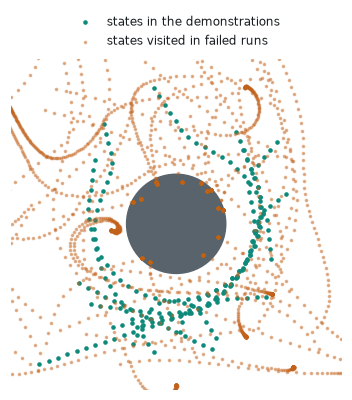

In [3]:
X0, Y0 = toy.demonstrations(np.random.default_rng(10), 10, KIND); policy = toy.Policy().fit(X0, Y0)
rate, paths, ok = toy.rollout(policy, starts, targets, KIND, record=True); print(f"success after 10 demonstrations: {rate:.0%}")
plt.figure(figsize=(3.9, 3.9)); plt.gca().add_patch(plt.Circle(toy.C0, toy.R, color="#59636B")); plt.scatter(X0[:, 0], X0[:, 1], s=4, color=style.TEAL, label="states in the demonstrations")
bad = paths[:, ~ok][:, :40].reshape(-1, 2); plt.scatter(bad[:, 0], bad[:, 1], s=2, color=style.ORANGE, alpha=0.4, label="states visited in failed runs")
plt.xlim(0, 1); plt.ylim(0, 1); plt.gca().set_aspect("equal"); style.bare(plt.gca()); plt.legend(fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1)); plt.show()

## Two ways to spend the same labelling budget

Each round adds 300 labelled steps.

- **More demonstrations**: the expert performs new episodes from scratch.
- **Corrections**: run the current policy, take states from the episodes where it failed, and ask the
  expert what it would have done there. This is DAgger.

more demonstrations  ['10%', '33%', '60%', '71%', '77%', '87%']
corrections          ['10%', '30%', '70%', '92%', '95%', '96%']


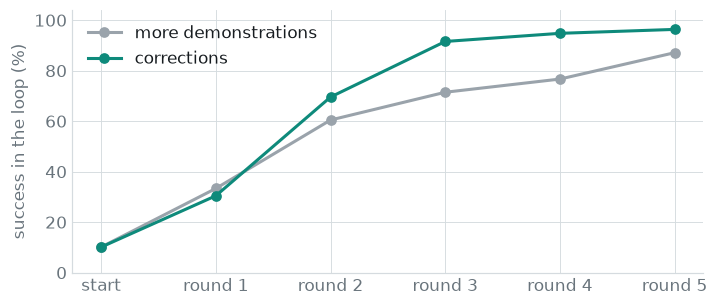

In [4]:
def failed_states(pol, rng, n_episodes=60):
    P, T = toy.sample_pairs(rng, n_episodes); _, paths, ok = toy.rollout(pol, P, T, KIND, record=True); src = ~ok if (~ok).any() else np.ones(len(ok), bool)
    return paths[:-1, src].reshape(-1, 2), np.tile(T[src], (len(paths) - 1, 1)), 1 - ok.mean()

rounds, budget = 5, 300; curves = {"more demonstrations": [], "corrections": []}; fail_rates = []
for seed in range(3):
    Xs, Ys = toy.demonstrations(np.random.default_rng(10 + seed), 10, KIND)
    for arm in curves:
        X, Y = Xs.copy(), Ys.copy(); rng = np.random.default_rng(500 + seed); pol = toy.Policy(seed=seed).fit(X, Y); c = [toy.rollout(pol, starts, targets, KIND)]
        for r in range(rounds):
            if arm == "more demonstrations":
                Xn, Yn = toy.demonstrations(rng, 12, KIND); Xn, Yn = Xn[:budget], Yn[:budget]
            else:
                Sv, Tv, fr = failed_states(pol, rng); pick = rng.choice(len(Sv), min(budget, len(Sv)), replace=False); Xn = toy.features(Sv[pick], Tv[pick], KIND); Yn = toy.expert(Sv[pick], Tv[pick]); fail_rates.append((r, fr))
            X, Y = np.concatenate([X, Xn]), np.concatenate([Y, Yn]); pol = toy.Policy(seed=seed).fit(X, Y); c.append(toy.rollout(pol, starts, targets, KIND))
        curves[arm].append(c)
plt.figure(figsize=(7.4, 3.1))
for (name, c), col in zip(curves.items(), (style.GREY, style.TEAL)): plt.plot(np.mean(c, 0) * 100, marker="o", color=col, label=name); print(f"{name:20s}", [f"{v:.0%}" for v in np.mean(c, 0)])
plt.xticks(range(rounds + 1), ["start"] + [f"round {i}" for i in range(1, rounds + 1)]); plt.ylim(0, 104); plt.ylabel("success in the loop (%)"); plt.legend(); plt.show()

The two strategies cost the same in expert effort. The corrections land where the policy's errors are.

## The flywheel's built-in limit

In [5]:
fr = np.array(fail_rates); print("share of episodes that fail during collection, by round:", [f"{fr[fr[:, 0] == r, 1].mean():.0%}" for r in range(rounds)])

share of episodes that fail during collection, by round: ['84%', '69%', '36%', '9%', '7%']


As the policy improves it fails less, so each turn of the wheel finds fewer failures to learn from.
The same amount of useful data takes more and more robot hours.

## Training on it without breaking what worked

A policy trained on targets in the left half of the workspace is updated with data for the right half.
Continue training on the new data alone, or retrain on old and new together?

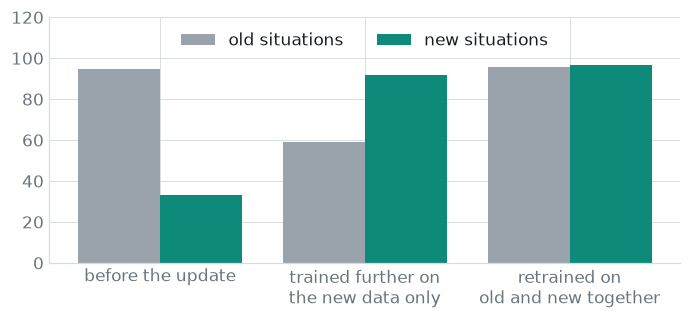

before         old situations 94%   new situations 33%
new data only  old situations 59%   new situations 92%
old and new    old situations 96%   new situations 96%


In [6]:
def half(rng, n, left):
    P, T = [], []
    while len(P) < n:
        p, t = toy.sample_pairs(rng, 1)
        if (t[0, 0] < 0.5) == left: P.append(p[0]); T.append(t[0])
    return np.array(P), np.array(T)
def demos_for(P, T):
    X, Y = [], []
    for p, t in zip(P, T):
        for _ in range(90):
            a = toy.expert(p, t); X.append(toy.features(p[None], t[None], KIND)[0]); Y.append(a); p = p + a
            if np.linalg.norm(p - t) < 0.02: break
    return np.array(X), np.array(Y)
rng = np.random.default_rng(0); test_old, test_new = half(np.random.default_rng(1), 200, True), half(np.random.default_rng(2), 200, False)
Xo, Yo = demos_for(*half(rng, 100, True)); Xn, Yn = demos_for(*half(rng, 100, False)); score = lambda p: (toy.rollout(p, *test_old, KIND) * 100, toy.rollout(p, *test_new, KIND) * 100)
before = toy.Policy().fit(Xo, Yo); continued = copy.deepcopy(before); continued.net.set_params(warm_start=True); continued.fit(Xn, Yn); together = toy.Policy().fit(np.concatenate([Xo, Xn]), np.concatenate([Yo, Yn]))
res = np.array([score(before), score(continued), score(together)]); x = np.arange(3); plt.figure(figsize=(7.4, 2.9))
plt.bar(x - 0.2, res[:, 0], 0.4, color=style.GREY, label="old situations"); plt.bar(x + 0.2, res[:, 1], 0.4, color=style.TEAL, label="new situations")
plt.xticks(x, ["before the update", "trained further on\nthe new data only", "retrained on\nold and new together"]); plt.ylim(0, 120); plt.legend(ncol=2, loc="upper center"); plt.show()
for name, r in zip(("before", "new data only", "old and new"), res): print(f"{name:14s} old situations {r[0]:.0f}%   new situations {r[1]:.0f}%")

Training on the new data alone damages what the policy knew. This is catastrophic forgetting, and it is
why every fixed failure should stay in the test suite.

## Things to try

- Sample corrections from all episodes, not only failed ones. How much of the advantage remains?
- Weight the corrections three times as heavily as the original demonstrations.
- Cap the correction data at 50 steps per round. Is a little targeted data still better than a lot of ordinary data?